# Caso 2: Reconocimiento de rostros con Eigenfaces (PCA)
**Actividad 05 · Aprendizaje de Máquina · UNAP**

Dataset: *Olivetti Faces* (400 fotos de 64×64 px, 40 personas, 10 fotos por persona).
Restricción de la actividad: **sin redes neuronales**. Usamos PCA para obtener las *eigenfaces*
y un clasificador clásico (1-NN y SVM) sobre las coordenadas PCA.

Plan:
1. Separar entrenamiento y prueba (8 y 2 fotos por persona).
2. Ajustar PCA **solo con entrenamiento** y mirar la cara media y las eigenfaces.
3. Elegir el número de componentes con validación cruzada.
4. Entrenar y evaluar en el conjunto de prueba.

In [1]:
import os, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_olivetti_faces
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC

SEED = 42
os.makedirs("figuras", exist_ok=True)
os.makedirs("resultados", exist_ok=True)

## 1. Datos y partición

In [2]:
faces = fetch_olivetti_faces(shuffle=False)
X, y, imgs = faces.data, faces.target, faces.images
print("X:", X.shape, "| imágenes:", imgs.shape, "| personas:", len(np.unique(y)))

Xtr, Xte, ytr, yte, itr, ite = train_test_split(
    X, y, np.arange(len(y)), test_size=0.2, stratify=y, random_state=SEED)
print("Entrenamiento:", Xtr.shape, "| Prueba:", Xte.shape)

downloading Olivetti faces from https://ndownloader.figshare.com/files/5976027 to C:\Users\WINDOWS\scikit_learn_data


X: (400, 4096) | imágenes: (400, 64, 64) | personas: 40
Entrenamiento: (320, 4096) | Prueba: (80, 4096)


## 2. PCA y eigenfaces
Cada foto es un punto de 4096 dimensiones. PCA busca las direcciones donde las caras más varían;
cada una de esas direcciones, vista como imagen, es una *eigenface*.

Componentes para 90% de varianza: 62 | para 95%: 111


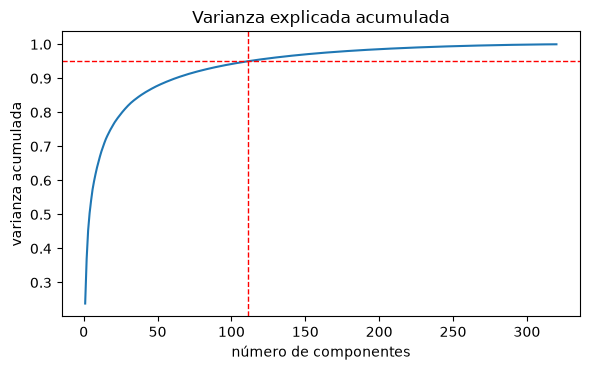

In [3]:
pca_full = PCA(svd_solver="full").fit(Xtr)
cum = np.cumsum(pca_full.explained_variance_ratio_)
n90 = int(np.argmax(cum >= 0.90) + 1)
n95 = int(np.argmax(cum >= 0.95) + 1)
print(f"Componentes para 90% de varianza: {n90} | para 95%: {n95}")

plt.figure(figsize=(6, 3.8))
plt.plot(np.arange(1, len(cum) + 1), cum)
plt.axhline(0.95, ls="--", c="red", lw=1); plt.axvline(n95, ls="--", c="red", lw=1)
plt.xlabel("número de componentes"); plt.ylabel("varianza acumulada")
plt.title("Varianza explicada acumulada")
plt.tight_layout(); plt.savefig("figuras/caso2_varianza.png", dpi=150); plt.show()

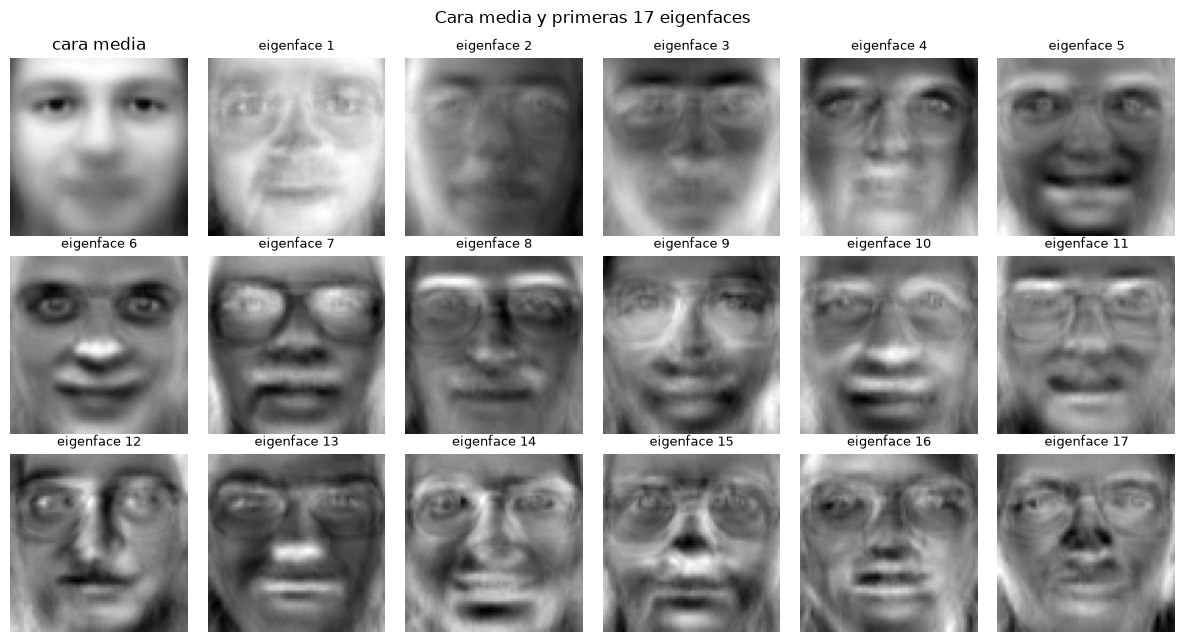

In [4]:
fig, axes = plt.subplots(3, 6, figsize=(12, 6.5))
axes[0, 0].imshow(pca_full.mean_.reshape(64, 64), cmap="gray"); axes[0, 0].set_title("cara media")
for i, ax in enumerate(axes.ravel()[1:]):
    ax.imshow(pca_full.components_[i].reshape(64, 64), cmap="gray")
    ax.set_title(f"eigenface {i + 1}", fontsize=9)
for ax in axes.ravel():
    ax.axis("off")
plt.suptitle("Cara media y primeras 17 eigenfaces")
plt.tight_layout(); plt.savefig("figuras/caso2_eigenfaces.png", dpi=150); plt.show()

## 3. Reconstrucción con pocos componentes
Una cara de prueba reconstruida con 5, 20, 50, 100 y 200 componentes: más componentes, más detalle.

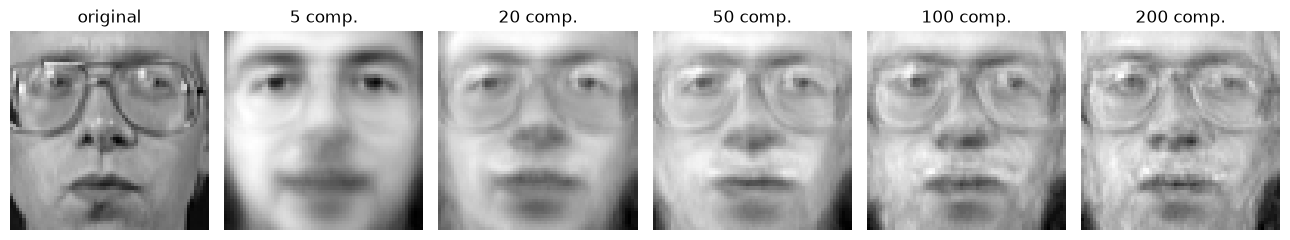

In [5]:
muestra = Xte[0]
ns = [5, 20, 50, 100, 200]
fig, axes = plt.subplots(1, len(ns) + 1, figsize=(13, 2.8))
axes[0].imshow(muestra.reshape(64, 64), cmap="gray"); axes[0].set_title("original")
for ax, n in zip(axes[1:], ns):
    p = PCA(n_components=n, svd_solver="full").fit(Xtr)
    rec = p.inverse_transform(p.transform(muestra[None, :]))[0]
    ax.imshow(rec.reshape(64, 64), cmap="gray"); ax.set_title(f"{n} comp.")
for ax in axes:
    ax.axis("off")
plt.tight_layout(); plt.savefig("figuras/caso2_reconstruccion.png", dpi=150); plt.show()

## 4. Elegir el número de componentes (validación cruzada en entrenamiento)
Probamos 1-NN sobre las coordenadas PCA con distintos números de componentes.
Usamos solo el conjunto de entrenamiento para decidir; la prueba queda intacta hasta el final.

CV por componentes: {5: 0.691, 10: 0.856, 20: 0.909, 30: 0.912, 40: 0.916, 60: 0.909, 80: 0.909, 100: 0.903, 150: 0.903}
Mejor n = 40 | 1-NN con píxeles crudos (CV): 0.903


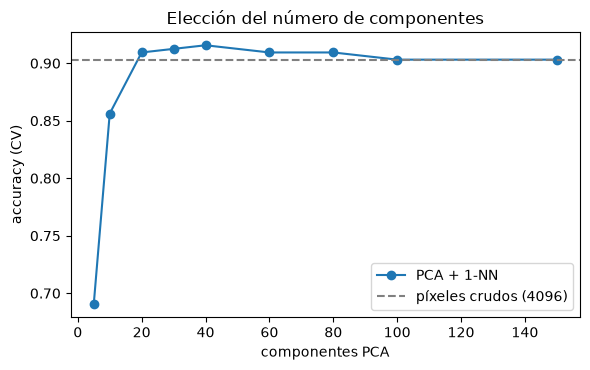

In [6]:
skf = StratifiedKFold(n_splits=4, shuffle=True, random_state=SEED)
valores_n = [5, 10, 20, 30, 40, 60, 80, 100, 150]
cv_knn = {}
for n in valores_n:
    pipe = make_pipeline(PCA(n_components=n, svd_solver="full"), KNeighborsClassifier(1))
    cv_knn[n] = float(cross_val_score(pipe, Xtr, ytr, cv=skf).mean())
mejor_n = max(cv_knn, key=cv_knn.get)

pix_cv = float(cross_val_score(KNeighborsClassifier(1), Xtr, ytr, cv=skf).mean())
print("CV por componentes:", {k: round(v, 3) for k, v in cv_knn.items()})
print("Mejor n =", mejor_n, "| 1-NN con píxeles crudos (CV):", round(pix_cv, 3))

plt.figure(figsize=(6, 3.8))
plt.plot(list(cv_knn.keys()), list(cv_knn.values()), "o-", label="PCA + 1-NN")
plt.axhline(pix_cv, ls="--", c="gray", label="píxeles crudos (4096)")
plt.xlabel("componentes PCA"); plt.ylabel("accuracy (CV)")
plt.title("Elección del número de componentes"); plt.legend()
plt.tight_layout(); plt.savefig("figuras/caso2_cv_componentes.png", dpi=150); plt.show()

## 5. SVM sobre eigenfaces (búsqueda de hiperparámetros)

In [7]:
pipe_svm = make_pipeline(PCA(whiten=True, svd_solver="full"), SVC(kernel="rbf"))
grid = GridSearchCV(pipe_svm, {
    "pca__n_components": [40, 80, 120],
    "svc__C": [1, 10, 100],
    "svc__gamma": ["scale", 0.01],
}, cv=skf, n_jobs=-1)
t0 = time.time(); grid.fit(Xtr, ytr)
print("Mejores parámetros:", grid.best_params_, "| CV:", round(grid.best_score_, 3),
      "| tiempo: %.1fs" % (time.time() - t0))

Mejores parámetros: {'pca__n_components': 40, 'svc__C': 10, 'svc__gamma': 0.01} | CV: 0.963 | tiempo: 5.2s


## 6. Evaluación final en el conjunto de prueba

In [8]:
knn_pca = make_pipeline(PCA(n_components=mejor_n, svd_solver="full"), KNeighborsClassifier(1)).fit(Xtr, ytr)
knn_pix = KNeighborsClassifier(1).fit(Xtr, ytr)

acc_knn = float((knn_pca.predict(Xte) == yte).mean())
acc_svm = float((grid.predict(Xte) == yte).mean())
acc_pix = float((knn_pix.predict(Xte) == yte).mean())
print(f"1-NN en píxeles crudos : {acc_pix:.3f}")
print(f"PCA ({mejor_n}) + 1-NN       : {acc_knn:.3f}")
print(f"PCA + SVM (grid)       : {acc_svm:.3f}")

1-NN en píxeles crudos : 0.925
PCA (40) + 1-NN       : 0.912
PCA + SVM (grid)       : 0.988


Errores del SVM: 1 de 80


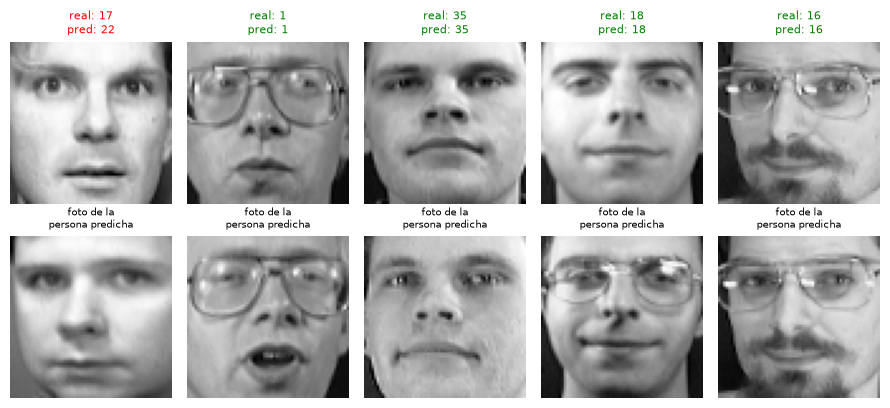

In [9]:
pred = grid.predict(Xte)
n_err = int((pred != yte).sum())
print("Errores del SVM:", n_err, "de", len(yte))

sel = list(np.where(pred != yte)[0][:4]) + list(np.where(pred == yte)[0][:4])
fig, axes = plt.subplots(2, len(sel), figsize=(1.8 * len(sel), 4.2))
for j, i in enumerate(sel):
    ok = pred[i] == yte[i]
    axes[0, j].imshow(imgs[ite[i]], cmap="gray")
    axes[0, j].set_title(f"real: {yte[i]}\npred: {pred[i]}", fontsize=8, color="green" if ok else "red")
    ej = imgs[itr[np.where(ytr == pred[i])[0][0]]]
    axes[1, j].imshow(ej, cmap="gray"); axes[1, j].set_title("foto de la\npersona predicha", fontsize=7)
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout(); plt.savefig("figuras/caso2_predicciones.png", dpi=150); plt.show()

In [10]:
def reconocer(i_test):
    """Dada la posición de una foto de prueba, devuelve la persona que predice el sistema."""
    return int(grid.predict(Xte[i_test:i_test + 1])[0]), int(yte[i_test])

print("Ejemplo reconocer(0) -> (predicha, real):", reconocer(0))

with open("resultados/caso2.json", "w", encoding="utf-8") as f:
    json.dump({
        "n_total": int(len(y)), "n_personas": int(len(np.unique(y))),
        "n_train": int(len(ytr)), "n_test": int(len(yte)),
        "n90": n90, "n95": n95,
        "cv_knn": {str(k): v for k, v in cv_knn.items()}, "mejor_n": int(mejor_n),
        "pix_cv": pix_cv, "acc_pix_test": acc_pix, "acc_knn_test": acc_knn,
        "acc_svm_test": acc_svm, "svm_params": {k: (v if isinstance(v, str) else float(v))
                                                for k, v in grid.best_params_.items()},
        "svm_cv": float(grid.best_score_), "errores_svm": n_err,
    }, f, ensure_ascii=False, indent=2)
print("Resultados guardados en resultados/caso2.json")

Ejemplo reconocer(0) -> (predicha, real): (1, 1)
Resultados guardados en resultados/caso2.json


## Conclusión del caso
- PCA + 1-NN quedó cerca, pero por debajo de 1-NN con los píxeles crudos; reducir dimensiones no mejoró su exactitud.
- El SVM sobre las coordenadas PCA fue el mejor clasificador en la prueba.
- Usamos PCA y clasificadores clásicos; no usamos redes neuronales.